In [1]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from math import sqrt
import seaborn as sns
import numpy as np


from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import BayesianRidge
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')


#Choose whether to save plots
save_plots = False

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out





In [ ]:
season_map = {
    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Spring',
    4: 'Spring',
    5: 'Spring',
    6: 'Summer',
    7: 'Summer',
    8: 'Summer',
    9: 'Fall',
    10: 'Fall',
    11: 'Fall',
}
datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"

hourly = pd.read_csv(datapath+"fulldat-hourly-timeseries.csv")
hourly['datetime'] = pd.to_datetime(hourly['datetime'], errors='coerce')
hourly['weekday'] = hourly['datetime'].dt.weekday
hourly['hour'] = hourly['datetime'].dt.hour


hourly_grouped = hourly.groupby(['hour','weekday']).agg(
    sfc_no2_mean = ('sfc_no2_mean', 'mean'),
    col_no2_mean = ('col_no2_mean', 'mean')
)

estimates = pd.read_csv(datapath+'monthly-no2-estimates.csv')
estimates['datetime'] = pd.to_datetime(estimates['datetime'], errors='coerce')
estimates['weekday'] = estimates['datetime'].dt.weekday
estimates['hour'] = estimates['datetime'].dt.hour

estimate_grouped = estimates.groupby(['hour','weekday']).agg(
    est_no2_mean = ('no2_estimate', 'mean')
)


In [15]:
estimate_grouped

est_no2_mean
hour weekday              
11   0           16.991311
     2           17.376532
     3           16.971895
     4           16.321710
     5           17.401639
...                    ...
23   2           13.619791
     3           16.246839
     4           15.157704
     5           14.678752
     6           15.482460

[89 rows x 1 columns]

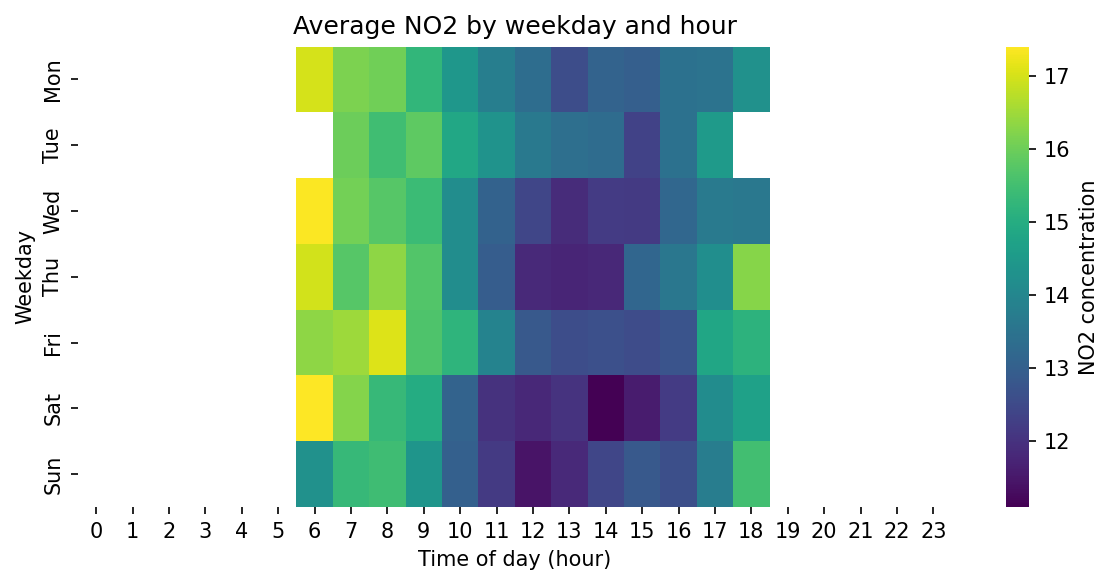

In [14]:
# Subset data
subset = estimate_grouped.reset_index().copy()
# subset = subset[(subset['hour'] >= 6) & (subset['hour'] <= 19)].copy()
subset['hour'] = subset['hour'] - 5

# Pivot to a weekday-by-hour matrix
heatmap_data = (
    subset.pivot(index="weekday", columns="hour", values="est_no2_mean")
    .reindex(index=range(7), columns=range(0, 24))
)

# Plot a heatmap with time of day on the x-axis and weekday on the y-axis
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(
    heatmap_data,
    cmap="viridis",
    ax=ax,
    cbar_kws={"label": "NO2 concentration"},
    xticklabels=range(0, 24),
    yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
)
ax.set_xlabel("Time of day (hour)")
ax.set_ylabel("Weekday")
ax.set_title("Average NO2 by weekday and hour")
plt.tight_layout()
plt.show()

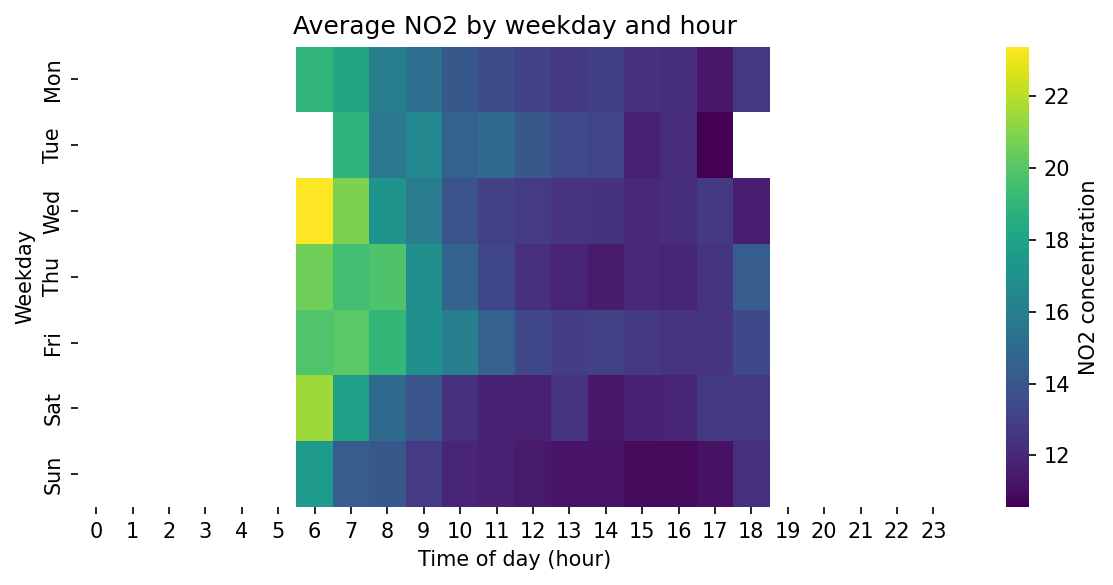

In [27]:
# Subset data
subset = hourly_grouped.reset_index().copy()
# subset = subset[(subset['hour'] >= 6) & (subset['hour'] <= 19)].copy()
subset['hour'] = subset['hour'] - 5

# Pivot to a weekday-by-hour matrix
heatmap_data = (
    subset.pivot(index="weekday", columns="hour", values="sfc_no2_mean")
    .reindex(index=range(7), columns=range(0, 24))
)

# Plot a heatmap with time of day on the x-axis and weekday on the y-axis
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(
    heatmap_data,
    cmap="viridis",
    ax=ax,
    cbar_kws={"label": "NO2 concentration"},
    xticklabels=range(0, 24),
    yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
)
ax.set_xlabel("Time of day (hour)")
ax.set_ylabel("Weekday")
ax.set_title("Average NO2 by weekday and hour")
plt.tight_layout()
plt.show()

In [17]:
combined = pd.read_csv("/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/fulldat-unaggregated.csv")
combined['datetime'] = pd.to_datetime(combined['datetime'], errors='coerce', utc=True).dt.tz_convert('America/Chicago')
combined.drop(columns=combined.columns[0], inplace=True)

hourly_dat = (
    combined.set_index('datetime')
    .groupby([pd.Grouper('datetime', freq='1h'), 'latitude', 'longitude'])
    .agg( 
        col_no2_mean=('column_no2', 'mean'),
        col_no2_median=('column_no2', 'median'),
        col_no2_var=('column_no2', 'var'),
        col_no2_sd=('column_no2', 'std'),
        sfc_no2_mean=('sfc_no2', 'mean'),
        sfc_no2_median=('sfc_no2', 'median'),
        sfc_no2_var=('sfc_no2', 'var'),
        sfc_no2_sd=('sfc_no2', 'std'),
        pbl_mean=('pbl_height', 'mean'), 
        pbl_median=('pbl_height', 'median'),
        solar_zenith_mean=('solar_zenith_angle', 'mean'), 
        solar_zenith_median=('solar_zenith_angle', 'median'),
        u2m_mean=('U2M','mean'),
        u2m_median=('U2M','median'),
        v2m_mean=('V2M','mean'),
        v2m_median=('V2M','median'),
        u10m_mean=('U10M','mean'),
        u10m_median=('U10M','median'),
        v10m_mean=('V10M','mean'),
        v10m_median=('V10M','median')
        ).reset_index()
)

hourly_dat['hour'] = hourly_dat['datetime'].dt.hour
hourly_dat['weekday'] = hourly_dat['datetime'].dt.weekday

hourly_grouped = hourly_dat.groupby(['hour','weekday']).agg(
    sfc_no2_mean = ('sfc_no2_mean', 'mean'),
    col_no2_mean = ('col_no2_mean', 'mean')
)


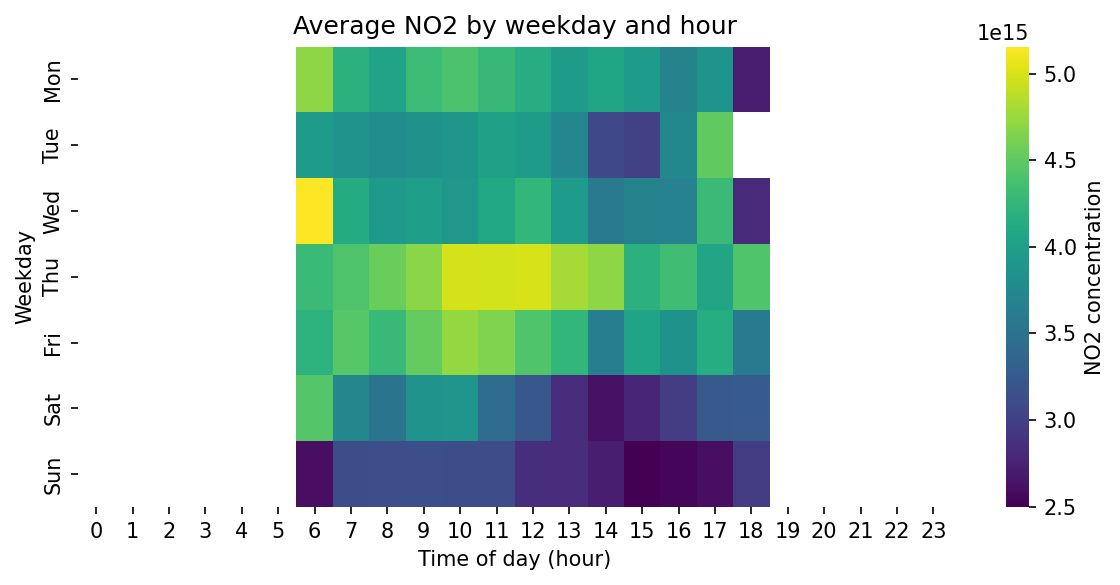

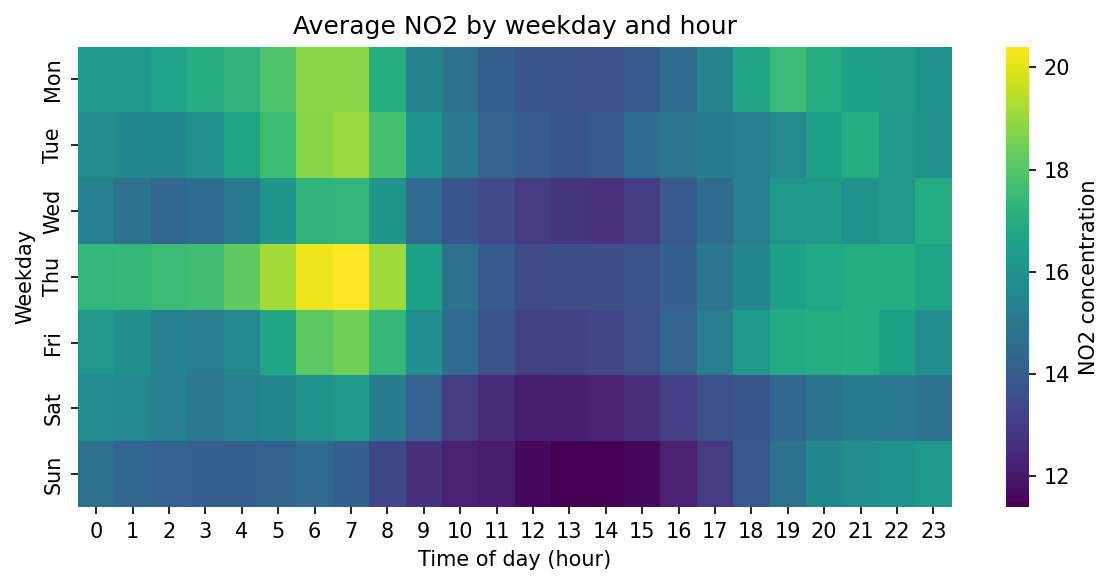

In [18]:
# Subset data
subset = hourly_grouped.reset_index().copy()
# subset['hour'] = subset['hour'] - 5

# Pivot to a weekday-by-hour matrix
heatmap_data = (
    subset.pivot(index="weekday", columns="hour", values="col_no2_mean")
    .reindex(index=range(7), columns=range(0, 24))
)

# Plot a heatmap with time of day on the x-axis and weekday on the y-axis
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(
    heatmap_data,
    cmap="viridis",
    ax=ax,
    cbar_kws={"label": "NO2 concentration"},
    xticklabels=range(0, 24),
    yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
)
ax.set_xlabel("Time of day (hour)")
ax.set_ylabel("Weekday")
ax.set_title("Average NO2 by weekday and hour")
plt.tight_layout()
plt.show()

# Pivot to a weekday-by-hour matrix
heatmap_data = (
    subset.pivot(index="weekday", columns="hour", values="sfc_no2_mean")
    .reindex(index=range(7), columns=range(0, 24))
)

# Plot a heatmap with time of day on the x-axis and weekday on the y-axis
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(
    heatmap_data,
    cmap="viridis",
    ax=ax,
    cbar_kws={"label": "NO2 concentration"},
    xticklabels=range(0, 24),
    yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
)
ax.set_xlabel("Time of day (hour)")
ax.set_ylabel("Weekday")
ax.set_title("Average NO2 by weekday and hour")
plt.tight_layout()
plt.show()